# 04 Rotation map zones: Part A (build years only)
Build years = 1999-01-04 to 2020-12-31. **Nothing dated 2021 or later is loaded or computed here** (the file is filtered while reading; checkpoints without a full next-month outcome are dropped and counted).

**This measures labels, not a trading strategy. No trading costs are applied.** An average excess under about 0.2% a month would likely not survive the 0.10%-per-trade cost in practice.

Rules, copied from the dashboard:
- **Change over n days** = close on the checkpoint / close n trading days earlier - 1 (adjusted close).
- **Sector average** for a window = simple mean of that window's change across the sector funds existing on the checkpoint date (funds that have a price n days back). **Excess** = a fund's change minus the sector average's change, same window.
- **3-month map:** longer = 63-day excess, shorter = 21-day excess. **1-month map:** longer = 21-day excess, shorter = 5-day excess.
- **Zone:** longer >= 0 and shorter >= 0 -> **Leading**; longer >= 0 and shorter < 0 -> **Fading**; longer < 0 and shorter >= 0 -> **Improving**; otherwise **Lagging**.
- **Checkpoints:** the same 21-day grid as notebooks 02 and 03 (every 21st trading day counted from 1999-01-04). Every fund existing on the date with a full 63 days of history is labeled (this 63-day requirement is used for both maps, so both label the same fund-checkpoints).
- **Outcome:** excess vs the sector average from the NEXT day's close to 21 trading days after that (same one-day delay as notebook 03); the sector average for the outcome = simple mean of the sector funds' changes over that same span.
- **Zone moves:** each sector's 3-month-map zone at consecutive checkpoints (21 trading days apart, labeled at both). One step clockwise = Improving->Leading, Leading->Fading, Fading->Lagging, Lagging->Improving; counter-clockwise = the reverse; two-step jumps (Leading<->Lagging, Improving<->Fading) are counted separately; same zone = "stayed". All labeled checkpoints in the build years are used for moves (no outcome needed).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from rotation.data import load_prices, wide
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300)
R = config.RESULTS_DIR; R.mkdir(exist_ok=True)
N = 21; HIST = 63; DELAY = 1
SECT, IND = config.SECTORS, config.INDUSTRIES
ZONES = ["Improving", "Leading", "Fading", "Lagging"]            # clockwise order

## 1. Load build years only (11 sector funds + 4 industries, adjusted close)

In [2]:
df = load_prices(symbols=SECT + IND, fields=["adj_close"], end=config.BUILD_END)
assert df.date.max() <= pd.Timestamp(config.BUILD_END)
P = wide(df, "adj_close")[SECT + IND]
assert len(P) == 5536                      # same trading calendar as notebooks 02 and 03
n = len(P)
print(P.index.min().date(), "to", P.index.max().date(), "|", n, "days")

1999-01-04 to 2020-12-31 | 5536 days


## 2. Changes, sector averages, excess and outcomes

In [3]:
def chg(X, k):
    return X / X.shift(k) - 1
S = P[SECT]
sec_avg = {k: chg(S, k).mean(axis=1, skipna=True) for k in (5, 21, 63)}       # simple mean across sector funds existing (valid change)
excess = {k: chg(P, k).sub(sec_avg[k], axis=0) for k in (5, 21, 63)}
span = DELAY + N
out_excess = (P.shift(-span) / P.shift(-DELAY) - 1).sub((S.shift(-span) / S.shift(-DELAY) - 1).mean(axis=1, skipna=True), axis=0)   # close i+1 -> close i+22

def zone(longer, shorter):
    return np.where(longer >= 0, np.where(shorter >= 0, "Leading", "Fading"), np.where(shorter >= 0, "Improving", "Lagging"))

checks = [i for i in range(N, n, N) if i >= HIST]
rows = []
for i in checks:
    for s in P.columns:
        if pd.isna(P.iloc[i][s]) or pd.isna(P.iloc[i - HIST][s]):
            continue
        for mp, (lk, sk) in {"3-month": (63, 21), "1-month": (21, 5)}.items():
            lo, sh = excess[lk].iloc[i][s], excess[sk].iloc[i][s]
            rows.append(dict(window_map=mp, pos=i, date=P.index[i], symbol=s, group="sector" if s in SECT else "industry",
                             longer=lo, shorter=sh, outcome_excess=out_excess.iloc[i][s] if i + span <= n - 1 else np.nan))
obs = pd.DataFrame(rows)
obs["zone"] = zone(obs.longer.values, obs.shorter.values)
obs["year"] = obs.date.dt.year
obs["has_outcome"] = obs.outcome_excess.notna()
print("checkpoints:", len(checks), "| first", P.index[checks[0]].date(), "| last", P.index[checks[-1]].date())
no_out = [P.index[i].date().isoformat() for i in checks if i + span > n - 1]
print("checkpoints without a full next-month outcome inside the build years (dropped from results 1, 2, 4, 5):", no_out)
print("labeled fund-checkpoints:", obs[obs.window_map == "3-month"].groupby("group").size().to_dict(), "(per map)")
# independent hand check of the rules on one fund-checkpoint
i0 = checks[40]; s0 = "XLK"
def hand_change(s, k): return P.iloc[i0][s] / P.iloc[i0 - k][s] - 1
sec63 = np.mean([hand_change(s, 63) for s in SECT if pd.notna(P.iloc[i0 - 63][s]) and pd.notna(P.iloc[i0][s])])
sec21 = np.mean([hand_change(s, 21) for s in SECT if pd.notna(P.iloc[i0 - 21][s]) and pd.notna(P.iloc[i0][s])])
r = obs[(obs.window_map == "3-month") & (obs.pos == i0) & (obs.symbol == s0)].iloc[0]
assert abs(r.longer - (hand_change(s0, 63) - sec63)) < 1e-12 and abs(r.shorter - (hand_change(s0, 21) - sec21)) < 1e-12
a, b = i0 + DELAY, i0 + DELAY + N
hand_out = (P.iloc[b][s0] / P.iloc[a][s0] - 1) - np.mean([P.iloc[b][s] / P.iloc[a][s] - 1 for s in SECT if pd.notna(P.iloc[a][s]) and pd.notna(P.iloc[b][s])])
assert abs(r.outcome_excess - hand_out) < 1e-12
print("hand check passed for", s0, "on", P.index[i0].date(), "-> zone", r.zone)
obs.drop(columns=["pos"]).round(6).to_csv(R / "04_observations.csv", index=False)
obs.head()

checkpoints: 261 | first 1999-04-06 | last 2020-12-14
checkpoints without a full next-month outcome inside the build years (dropped from results 1, 2, 4, 5): ['2020-12-14']
labeled fund-checkpoints: {'industry': 763, 'sector': 2436} (per map)
hand check passed for XLK on 2002-08-08 -> zone Lagging


C:\Users\joyfu\AppData\Local\Temp\ipykernel_18528\3806872286.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  obs.drop(columns=["pos"]).round(6).to_csv(R / "04_observations.csv", index=False)


,window_map,pos,date,symbol,group,longer,shorter,outcome_excess,zone,year,has_outcome
0,3-month,63,1999-04-06,XLK,sector,0.115798,0.094162,-0.118512,Leading,1999,True
1,1-month,63,1999-04-06,XLK,sector,0.094162,0.043743,-0.118512,Leading,1999,True
2,3-month,63,1999-04-06,XLE,sector,0.012096,0.069604,0.095888,Leading,1999,True
3,1-month,63,1999-04-06,XLE,sector,0.069604,-0.021753,0.095888,Fading,1999,True
4,3-month,63,1999-04-06,XLV,sector,0.045429,-0.006096,-0.052852,Fading,1999,True


## 3. Result 1: average next-month excess by zone (3-month map, sectors)
Count, average next-month excess (percent), median, share that beat the average, and a rough 95% range for the average from resampling checkpoint dates (2,000 draws with replacement, fixed seed; funds at one checkpoint move together, so dates are resampled as blocks).

In [4]:
def zone_table(d, seed=0, n_boot=2000):
    d = d[d.has_outcome]
    dates = np.array(sorted(d.date.unique()))
    sums = d.pivot_table(index="date", columns="zone", values="outcome_excess", aggfunc="sum").reindex(dates).reindex(columns=ZONES).fillna(0.0)
    cnts = d.pivot_table(index="date", columns="zone", values="outcome_excess", aggfunc="count").reindex(dates).reindex(columns=ZONES).fillna(0.0)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(dates), size=(n_boot, len(dates)))
    out = []
    for z in ZONES:
        x = d[d.zone == z].outcome_excess
        if len(x) == 0:
            out.append(dict(zone=z, count=0)); continue
        bs = sums[z].values[idx].sum(axis=1) / np.where(cnts[z].values[idx].sum(axis=1) > 0, cnts[z].values[idx].sum(axis=1), np.nan)
        out.append(dict(zone=z, count=len(x), avg_excess_pct=x.mean() * 100, median_pct=x.median() * 100,
                        share_beat_avg_pct=(x > 0).mean() * 100, range95_low_pct=np.nanpercentile(bs, 2.5) * 100,
                        range95_high_pct=np.nanpercentile(bs, 97.5) * 100))
    o = pd.DataFrame(out)
    allx = d.outcome_excess
    o.loc[len(o)] = dict(zone="All labeled", count=len(allx), avg_excess_pct=allx.mean() * 100, median_pct=allx.median() * 100,
                         share_beat_avg_pct=(allx > 0).mean() * 100)
    return o
main = obs[(obs.window_map == "3-month") & (obs.group == "sector")]
t1 = zone_table(main)
t1.round(3).to_csv(R / "04_zones_3m_sectors.csv", index=False)
t1.round(3)

,zone,count,avg_excess_pct,median_pct,share_beat_avg_pct,range95_low_pct,range95_high_pct
0,Improving,372,0.044,0.008,50.269,-0.296,0.415
1,Leading,833,-0.193,-0.058,48.860,-0.408,0.025
2,Fading,378,0.108,-0.219,46.561,-0.295,0.474
3,Lagging,842,0.128,0.102,51.425,-0.132,0.376
4,All labeled,2425,0.002,-0.016,49.608,NaN,NaN


## 4. Result 2: year by year, average next-month excess per zone (percent; 3-month map, sectors)

In [5]:
d = main[main.has_outcome]
yy = d.groupby(["year", "zone"]).outcome_excess.agg(n="size", avg_excess_pct=lambda s: s.mean() * 100).reset_index()
yy.round(3).to_csv(R / "04_zones_by_year.csv", index=False)
wide_avg = yy.pivot(index="year", columns="zone", values="avg_excess_pct").reindex(columns=ZONES)
wide_n = yy.pivot(index="year", columns="zone", values="n").reindex(columns=ZONES)
print("average next-month excess (%) by year and zone:"); print(wide_avg.round(2).to_string())
print("\ncounts:"); print(wide_n.fillna(0).astype(int).to_string())
print("\nyears Improving > 0:", int((wide_avg.Improving > 0).sum()), "of", int(wide_avg.Improving.notna().sum()),
      "| years Improving > Leading:", int((wide_avg.Improving > wide_avg.Leading).sum()),
      "| years Fading < 0:", int((wide_avg.Fading < 0).sum()), "of", int(wide_avg.Fading.notna().sum()))

average next-month excess (%) by year and zone:
zone  Improving  Leading  Fading  Lagging
year                                     
1999      -1.43    -0.36    0.51     0.82
2000      -0.54    -0.96    2.80    -0.15
2001      -0.05    -0.65   -0.68     1.14
2002      -0.16    -0.74    0.39     0.64
2003      -0.20    -0.63   -0.34     0.78
2004       0.67    -0.34   -0.49     0.26
2005       0.68    -0.30    0.32    -0.16
2006       0.87    -1.09    0.27     0.41
2007      -1.13     0.72    1.23    -0.69
2008       0.19     0.26   -0.34    -0.15
2009       1.84    -0.59   -1.29     0.48
2010      -0.08     0.43   -0.10    -0.35
2011      -0.96     0.34    0.14     0.07
2012       0.38     0.18   -0.72    -0.03
2013       0.69    -0.07   -0.30    -0.16
2014       1.07     0.24   -0.15    -0.48
2015      -0.58    -0.59    0.28     0.62
2016      -0.03     0.32   -0.48    -0.05
2017      -0.20    -0.35    1.57    -0.23
2018      -0.69     0.29   -0.87     0.62
2019       0.10    -0.73    

## 5. Result 3: zone moves between consecutive checkpoints (3-month map, sectors)

In [6]:
m = obs[(obs.window_map == "3-month") & (obs.group == "sector")].sort_values(["symbol", "pos"]).copy()
m["prev_zone"] = m.groupby("symbol").zone.shift(1); m["prev_pos"] = m.groupby("symbol").pos.shift(1)
mv = m[(m.pos - m.prev_pos) == N].copy()                          # labeled at both consecutive checkpoints
CW = {("Improving", "Leading"), ("Leading", "Fading"), ("Fading", "Lagging"), ("Lagging", "Improving")}
CCW = {(b, a) for a, b in CW}
def kind(a, b):
    if a == b: return "stayed"
    if (a, b) in CW: return "clockwise (one step)"
    if (a, b) in CCW: return "counter-clockwise (one step)"
    return "two-step jump"
mv["move"] = [kind(a, b) for a, b in zip(mv.prev_zone, mv.zone)]
summ = mv.move.value_counts().reindex(["stayed", "clockwise (one step)", "counter-clockwise (one step)", "two-step jump"]).fillna(0).astype(int)
summ_tab = pd.DataFrame({"count": summ, "share_pct": summ / summ.sum() * 100})
summ_tab.round(2).to_csv(R / "04_zone_moves_summary.csv")
full = pd.crosstab(mv.prev_zone, mv.zone).reindex(index=ZONES, columns=ZONES).fillna(0).astype(int)
full.index.name = "from \\ to"
full.to_csv(R / "04_zone_moves_table.csv")
print("consecutive labeled pairs:", len(mv)); print(summ_tab.round(1).to_string()); print("\nfrom-zone (rows) to to-zone (columns):"); print(full.to_string())
chg_only = mv[mv.move != "stayed"]
print("\nzone changes:", len(chg_only), "| clockwise", int((mv.move == "clockwise (one step)").sum()), "vs counter-clockwise", int((mv.move == "counter-clockwise (one step)").sum()))

consecutive labeled pairs: 2425
                              count  share_pct
move                                          
stayed                          869       35.8
clockwise (one step)            831       34.3
counter-clockwise (one step)    353       14.6
two-step jump                   372       15.3

from-zone (rows) to to-zone (columns):
zone       Improving  Leading  Fading  Lagging
from \ to                                     
Improving         55      130      24      163
Leading           14      388     276      155
Fading            28      151      49      150
Lagging          275      165      25      377

zone changes: 1556 | clockwise 831 vs counter-clockwise 353


## 6. Information only (not judged against Z1-Z3): 1-month map for sectors; industries on both maps

In [7]:
info = {}
info["1-month map, sectors"] = zone_table(obs[(obs.window_map == "1-month") & (obs.group == "sector")])
info["3-month map, industries"] = zone_table(obs[(obs.window_map == "3-month") & (obs.group == "industry")])
info["1-month map, industries"] = zone_table(obs[(obs.window_map == "1-month") & (obs.group == "industry")])
parts = []
for k, v in info.items():
    print("===", k, "==="); print(v.round(3).to_string(index=False)); print()
    parts.append(v.assign(view=k))
pd.concat(parts)[["view"] + list(v.columns)].round(3).to_csv(R / "04_information_only.csv", index=False)
info_sec1 = info["1-month map, sectors"]; info_sec1.round(3).to_csv(R / "04_info_1m_sectors.csv", index=False)

=== 1-month map, sectors ===
       zone  count  avg_excess_pct  median_pct  share_beat_avg_pct  range95_low_pct  range95_high_pct
  Improving    427           0.093       0.021              50.117           -0.254             0.426
    Leading    792          -0.095      -0.020              49.242           -0.341             0.157
     Fading    413          -0.166      -0.036              49.395           -0.486             0.178
    Lagging    793           0.137      -0.015              49.811           -0.122             0.391
All labeled   2425           0.002      -0.016              49.608              NaN               NaN

=== 3-month map, industries ===
       zone  count  avg_excess_pct  median_pct  share_beat_avg_pct  range95_low_pct  range95_high_pct
  Improving    122           0.505       0.278              52.459           -0.526             1.520
    Leading    275          -0.138       0.150              50.909           -0.764             0.438
     Fading    122  

## 7. Result 5: chart, average next-month excess by zone (3-month map, sectors), 95% range as error bars

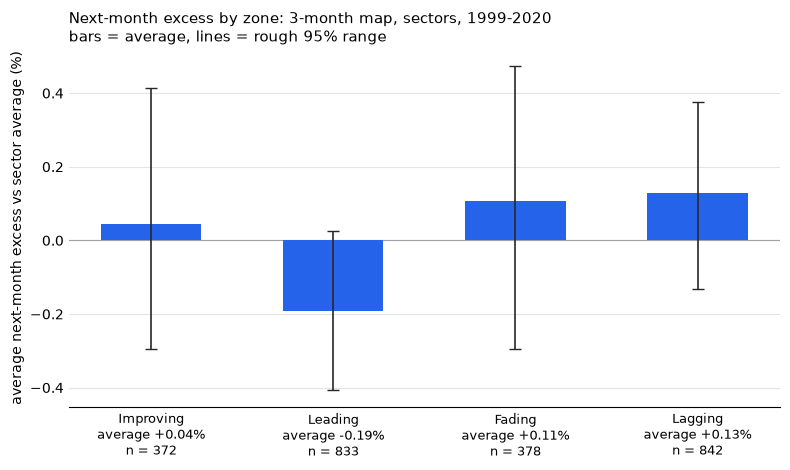

In [8]:
z = t1[t1.zone.isin(ZONES)].set_index("zone").reindex(ZONES)
fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(ZONES))
yerr = np.vstack([z.avg_excess_pct - z.range95_low_pct, z.range95_high_pct - z.avg_excess_pct])
ax.bar(x, z.avg_excess_pct, width=0.55, color="#2563eb", zorder=2)
ax.errorbar(x, z.avg_excess_pct, yerr=yerr, fmt="none", ecolor="#27272a", elinewidth=1.2, capsize=4, zorder=3)
ax.axhline(0, color="#a1a1aa", lw=0.8, zorder=1)
ax.set_xticks(x); ax.set_xticklabels([f"{zn}\naverage {a:+.2f}%\nn = {int(c):,}" for zn, a, c in zip(ZONES, z.avg_excess_pct, z["count"])], fontsize=9.5)
ax.set_ylabel("average next-month excess vs sector average (%)")
ax.grid(axis="y", color="#e4e4e7", lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.tick_params(length=0)
ax.set_title("Next-month excess by zone: 3-month map, sectors, 1999-2020\nbars = average, lines = rough 95% range", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(R / "04_avg_excess_by_zone.png", dpi=150); plt.show()

## 8. Checks for the three Part A predictions

In [9]:
zz = t1.set_index("zone")
imp, lead, fad = zz.loc["Improving", "avg_excess_pct"], zz.loc["Leading", "avg_excess_pct"], zz.loc["Fading", "avg_excess_pct"]
print(f"Z1: Improving average {imp:+.3f}% per month (need > 0) and Leading {lead:+.3f}% (Improving must be higher) -> {'CONFIRMED' if (imp > 0 and imp > lead) else 'CONTRADICTED'}")
print(f"    Improving range {zz.loc['Improving','range95_low_pct']:+.3f}% to {zz.loc['Improving','range95_high_pct']:+.3f}% | Leading range {zz.loc['Leading','range95_low_pct']:+.3f}% to {zz.loc['Leading','range95_high_pct']:+.3f}%")
print(f"Z2: Fading average {fad:+.3f}% per month (need < 0) -> {'CONFIRMED' if fad < 0 else 'CONTRADICTED'}   range {zz.loc['Fading','range95_low_pct']:+.3f}% to {zz.loc['Fading','range95_high_pct']:+.3f}%")
cwn, ccwn = int((mv.move == "clockwise (one step)").sum()), int((mv.move == "counter-clockwise (one step)").sum())
print(f"Z3: clockwise {cwn} vs counter-clockwise {ccwn} one-step moves (need clockwise > counter-clockwise) -> {'CONFIRMED' if cwn > ccwn else 'CONTRADICTED'}")
print(f"    (two-step jumps: {int((mv.move == 'two-step jump').sum())}; stayed: {int((mv.move == 'stayed').sum())})")

Z1: Improving average +0.044% per month (need > 0) and Leading -0.193% (Improving must be higher) -> CONFIRMED
    Improving range -0.296% to +0.415% | Leading range -0.408% to +0.025%
Z2: Fading average +0.108% per month (need < 0) -> CONTRADICTED   range -0.295% to +0.474%
Z3: clockwise 831 vs counter-clockwise 353 one-step moves (need clockwise > counter-clockwise) -> CONFIRMED
    (two-step jumps: 372; stayed: 869)


## 9. Extra context (not a prediction): is the clockwise tendency just built into the zone rules?
Zones come from overlapping windows (the 21-day move is part of the 63-day move), which can make clockwise moves common even with no real pattern. To see how much, the trading days of the 9 sector funds that exist for the whole period are shuffled into random order (200 times, fixed seed), which removes any real pattern but keeps each day's cross-section of returns; zone moves are then recounted with the same rules and grid. The real data is recounted on the same 9 funds for a fair comparison.

In [10]:
core = [s for s in SECT if P[s].notna().all()]
def move_counts(Pc):
    ch = lambda k: Pc / Pc.shift(k) - 1
    ex63 = ch(63).sub(ch(63).mean(axis=1), axis=0).iloc[checks].values
    ex21 = ch(21).sub(ch(21).mean(axis=1), axis=0).iloc[checks].values
    zc = np.where(ex63 >= 0, np.where(ex21 >= 0, 1, 2), np.where(ex21 >= 0, 0, 3))      # Improving 0, Leading 1, Fading 2, Lagging 3 (clockwise = +1)
    d = (zc[1:] - zc[:-1]) % 4
    return dict(stayed=int((d == 0).sum()), cw=int((d == 1).sum()), ccw=int((d == 3).sum()), two_step=int((d == 2).sum()))
real = move_counts(P[core])
rets = P[core].pct_change().iloc[1:].values
rng = np.random.default_rng(0)
null = []
for _ in range(200):
    r = rets[rng.permutation(len(rets))]
    Ps = pd.DataFrame(np.vstack([np.ones((1, len(core))), np.cumprod(1 + r, axis=0)]), index=P.index, columns=core)
    null.append(move_counts(Ps))
null = pd.DataFrame(null)
null["cw_share_of_one_step"] = null.cw / (null.cw + null.ccw) * 100
real_share = real["cw"] / (real["cw"] + real["ccw"]) * 100
res = pd.DataFrame({"real (9 core funds)": {**real, "cw_share_of_one_step": real_share},
                    "shuffled days: average": null.mean(), "shuffled days: 2.5th pct": null.quantile(0.025), "shuffled days: 97.5th pct": null.quantile(0.975)}).T
res.round(1).to_csv(R / "04_zone_move_shuffle_check.csv")
print("9 core funds:", core); print(res.round(1).to_string())

9 core funds: ['XLK', 'XLE', 'XLV', 'XLU', 'XLF', 'XLI', 'XLB', 'XLP', 'XLY']
                           stayed     cw    ccw  two_step  cw_share_of_one_step
real (9 core funds)         860.0  802.0  328.0     350.0                  71.0
shuffled days: average      889.4  779.9  319.9     350.8                  70.9
shuffled days: 2.5th pct    841.0  741.0  292.0     316.0                  68.7
shuffled days: 97.5th pct   945.0  820.1  348.1     392.3                  73.0


---
# Part B: test years (2021-01-01 to the last date in the data)
Checked **once**. Predictions Y1-Y3 are in FINDINGS.md (written before this ran). Method is exactly Part A's: same rules, same 21-day grid **continuing from Part A**, same one-day delay, same 63-day history minimum, same zone definitions, same sector average (simple mean of the window's change across sector funds with a valid change).

Choices stated up front:
- Test checkpoints are the grid checkpoints dated 2021-01-01 or later; their look-backs may use late-2020 prices. Checkpoints whose next-month outcome runs past the end of the data are dropped and counted.
- Zone moves use only consecutive test checkpoints.
- The shuffled-days baseline shuffles only the test-year trading days of the 11 sector funds (all 11 exist throughout the test years); earlier days stay real; 200 shuffles, fixed seed; same rules and grid. The real clockwise share is measured on the same funds.
- Safeguard: the Part B code is run on the build years first and must reproduce every Part A number exactly.

In [11]:
P_START = config.TEST_START
P_END = None            # all data through the last date
OUT = config.RESULTS_DIR
R = OUT; R.mkdir(parents=True, exist_ok=True)               # Part B files are written with the 04b_ prefix
dfF = load_prices(symbols=SECT + IND, fields=["adj_close"], end=P_END)
PF = wide(dfF, "adj_close")[SECT + IND]
nF = len(PF)
print("loaded:", PF.index.min().date(), "to", PF.index.max().date(), "|", nF, "days")

loaded: 1999-01-04 to 2026-10-15 | 6989 days


## B-1. The Part A method as functions, with a guard

In [12]:
def build_obs(Pd):
    nn = len(Pd)
    Sd = Pd[SECT]
    sec_ = {k: chg(Sd, k).mean(axis=1, skipna=True) for k in (5, 21, 63)}
    exc_ = {k: chg(Pd, k).sub(sec_[k], axis=0) for k in (5, 21, 63)}
    out_ = (Pd.shift(-span) / Pd.shift(-DELAY) - 1).sub((Sd.shift(-span) / Sd.shift(-DELAY) - 1).mean(axis=1, skipna=True), axis=0)
    chk = [i for i in range(N, nn, N) if i >= HIST]
    rows_ = []
    for i in chk:
        for s in Pd.columns:
            if pd.isna(Pd.iloc[i][s]) or pd.isna(Pd.iloc[i - HIST][s]):
                continue
            for mp, (lk, sk) in {"3-month": (63, 21), "1-month": (21, 5)}.items():
                lo, sh = exc_[lk].iloc[i][s], exc_[sk].iloc[i][s]
                rows_.append(dict(window_map=mp, pos=i, date=Pd.index[i], symbol=s, group="sector" if s in SECT else "industry",
                                  longer=lo, shorter=sh, outcome_excess=out_.iloc[i][s] if i + span <= nn - 1 else np.nan))
    o = pd.DataFrame(rows_)
    o["zone"] = zone(o.longer.values, o.shorter.values)
    o["year"] = o.date.dt.year
    o["has_outcome"] = o.outcome_excess.notna()
    return o, chk

def zone_moves(o3):
    m_ = o3.sort_values(["symbol", "pos"]).copy()
    m_["prev_zone"] = m_.groupby("symbol").zone.shift(1); m_["prev_pos"] = m_.groupby("symbol").pos.shift(1)
    mv_ = m_[(m_.pos - m_.prev_pos) == N].copy()
    mv_["move"] = [kind(a, b) for a, b in zip(mv_.prev_zone, mv_.zone)]
    sm = mv_.move.value_counts().reindex(["stayed", "clockwise (one step)", "counter-clockwise (one step)", "two-step jump"]).fillna(0).astype(int)
    st = pd.DataFrame({"count": sm, "share_pct": sm / sm.sum() * 100})
    fl = pd.crosstab(mv_.prev_zone, mv_.zone).reindex(index=ZONES, columns=ZONES).fillna(0).astype(int)
    fl.index.name = "from \\ to"
    return mv_, st, fl

def move_counts2(Pc, chk):
    ch = lambda k: Pc / Pc.shift(k) - 1
    ex63 = ch(63).sub(ch(63).mean(axis=1), axis=0).iloc[chk].values
    ex21 = ch(21).sub(ch(21).mean(axis=1), axis=0).iloc[chk].values
    assert not np.isnan(ex63).any() and not np.isnan(ex21).any()
    zc = np.where(ex63 >= 0, np.where(ex21 >= 0, 1, 2), np.where(ex21 >= 0, 0, 3))
    d = (zc[1:] - zc[:-1]) % 4
    return dict(stayed=int((d == 0).sum()), cw=int((d == 1).sum()), ccw=int((d == 3).sum()), two_step=int((d == 2).sum()))

def shuffle_check(Pdata, cols, chk, n_draws=200, seed=0, shuffle_from=None):
    Pc = Pdata[cols]
    real_ = move_counts2(Pc, chk)
    rng_ = np.random.default_rng(seed)
    null_ = []
    if shuffle_from is None:                                             # Part A: shuffle every day
        rets_ = Pc.pct_change().iloc[1:].values
        for _ in range(n_draws):
            r = rets_[rng_.permutation(len(rets_))]
            Ps = pd.DataFrame(np.vstack([np.ones((1, len(cols))), np.cumprod(1 + r, axis=0)]), index=Pc.index, columns=cols)
            null_.append(move_counts2(Ps, chk))
    else:                                                                # Part B: shuffle only the days from row `shuffle_from` on
        base = Pc.iloc[:shuffle_from].values
        rets_ = Pc.pct_change().iloc[shuffle_from:].values
        last = Pc.iloc[shuffle_from - 1].values
        for _ in range(n_draws):
            r = rets_[rng_.permutation(len(rets_))]
            Ps = pd.DataFrame(np.vstack([base, last * np.cumprod(1 + r, axis=0)]), index=Pc.index, columns=cols)
            null_.append(move_counts2(Ps, chk))
    null_ = pd.DataFrame(null_)
    null_["cw_share_of_one_step"] = null_.cw / (null_.cw + null_.ccw) * 100
    real_["cw_share_of_one_step"] = real_["cw"] / (real_["cw"] + real_["ccw"]) * 100
    return real_, null_

def fading_vs_overall(d, seed=0, n_boot=2000):
    d = d[d.has_outcome]
    dates = np.array(sorted(d.date.unique()))
    g = d.assign(f=(d.zone == "Fading")).groupby("date")
    sa = g.outcome_excess.sum().reindex(dates).values; ca = g.outcome_excess.count().reindex(dates).values.astype(float)
    sf = d[d.zone == "Fading"].groupby("date").outcome_excess.sum().reindex(dates).fillna(0).values
    cf = d[d.zone == "Fading"].groupby("date").outcome_excess.count().reindex(dates).fillna(0).values.astype(float)
    idx = np.random.default_rng(seed).integers(0, len(dates), size=(n_boot, len(dates)))
    with np.errstate(invalid="ignore", divide="ignore"):
        bs = (sf[idx].sum(axis=1) / cf[idx].sum(axis=1) - sa[idx].sum(axis=1) / ca[idx].sum(axis=1)) * 100
    fa, ov = d[d.zone == "Fading"].outcome_excess.mean() * 100, d.outcome_excess.mean() * 100
    return dict(n_fading=int((d.zone == "Fading").sum()), n_all=len(d), fading_avg_pct=fa, overall_avg_pct=ov, fading_minus_overall_pct=fa - ov,
                range95_low_pct=np.nanpercentile(bs, 2.5), range95_high_pct=np.nanpercentile(bs, 97.5))

# ---- guard: the Part B code on the build years must reproduce every Part A number exactly ----
obsC, checksC = build_obs(P)
obsC["zone_check"] = obsC.zone
pd.testing.assert_frame_equal(obsC.drop(columns="zone_check").reset_index(drop=True), obs.reset_index(drop=True))
assert checksC == checks
mvC, summC, fullC = zone_moves(obs[(obs.window_map == "3-month") & (obs.group == "sector")])
pd.testing.assert_frame_equal(summC, summ_tab); pd.testing.assert_frame_equal(fullC, full)
pd.testing.assert_frame_equal(zone_table(obs[(obs.window_map == "3-month") & (obs.group == "sector")]), t1)
for k, name in (("1-month map, sectors", ("1-month", "sector")), ("3-month map, industries", ("3-month", "industry")), ("1-month map, industries", ("1-month", "industry"))):
    pd.testing.assert_frame_equal(zone_table(obs[(obs.window_map == name[0]) & (obs.group == name[1])]), info[k])
realC, nullC = shuffle_check(P, core, checks)
assert realC == {k: v for k, v in real.items()} or all(np.isclose(realC[k], real[k]) for k in real)
pd.testing.assert_frame_equal(nullC, null)
print("guard passed: Part B code reproduces every Part A number exactly (observations, zones, year tables inputs, moves, from-to table, information-only tables, shuffled-days check)")

guard passed: Part B code reproduces every Part A number exactly (observations, zones, year tables inputs, moves, from-to table, information-only tables, shuffled-days check)


## B-2. Test-period observations and period accounting

In [13]:
obsF, checksF = build_obs(PF)
test_checks = [i for i in checksF if PF.index[i] >= pd.Timestamp(P_START)]
dropped = [PF.index[i].date().isoformat() for i in test_checks if i + span > nF - 1]
obsT = obsF[obsF.date >= pd.Timestamp(P_START)].reset_index(drop=True)
print(f"checkpoints dated {pd.Timestamp(P_START).date()} or later: {len(test_checks)} | first {PF.index[test_checks[0]].date()} | last {PF.index[test_checks[-1]].date()}")
print(f"dropped from outcome results (outcome runs past the end of the data): {len(dropped)} {dropped}")
print("labeled fund-checkpoints with an outcome (per map):", obsT[(obsT.window_map == '3-month') & obsT.has_outcome].groupby('group').size().to_dict())
print("funds labeled at each checkpoint: min", obsT[(obsT.window_map == '3-month') & (obsT.group == 'sector')].groupby('date').size().min(),
      "max", obsT[(obsT.window_map == '3-month') & (obsT.group == 'sector')].groupby('date').size().max())
obsT.drop(columns=["pos"]).round(6).to_csv(R / "04b_observations.csv", index=False)
mainT = obsT[(obsT.window_map == "3-month") & (obsT.group == "sector")]
obsT.head(3)

checkpoints dated 2021-01-01 or later: 69 | first 2021-01-14 | last 2026-09-23
dropped from outcome results (outcome runs past the end of the data): 1 ['2026-09-23']
labeled fund-checkpoints with an outcome (per map): {'industry': 272, 'sector': 748}
funds labeled at each checkpoint: min 11 max 11


C:\Users\joyfu\AppData\Local\Temp\ipykernel_18528\2959931331.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  obsT.drop(columns=["pos"]).round(6).to_csv(R / "04b_observations.csv", index=False)


,window_map,pos,date,symbol,group,longer,shorter,outcome_excess,zone,year,has_outcome
0,3-month,5544,2021-01-14,XLK,sector,-0.064123,-0.014626,0.039679,Lagging,2021,True
1,1-month,5544,2021-01-14,XLK,sector,-0.014626,-0.015002,0.039679,Lagging,2021,True
2,3-month,5544,2021-01-14,XLE,sector,0.355244,0.086946,0.052140,Leading,2021,True


## B-3. Result 1: 3-month map, sectors, average next-month excess by zone

In [14]:
t1B = zone_table(mainT)
t1B.round(3).to_csv(R / "04b_zones_3m_sectors.csv", index=False)
t1B.round(3)

,zone,count,avg_excess_pct,median_pct,share_beat_avg_pct,range95_low_pct,range95_high_pct
0,Improving,124,0.216,-0.511,44.355,-0.448,0.892
1,Leading,248,-0.319,-0.502,45.161,-0.840,0.167
2,Fading,104,-0.258,-0.536,46.154,-0.970,0.432
3,Lagging,272,0.290,0.158,52.941,-0.077,0.682
4,All labeled,748,-0.000,-0.130,47.995,NaN,NaN


## B-4. Result 2: year by year per zone (percent). The last year is partial.

In [15]:
dB = mainT[mainT.has_outcome]
yyB = dB.groupby(["year", "zone"]).outcome_excess.agg(n="size", avg_excess_pct=lambda s: s.mean() * 100).reset_index()
last_year = int(dB.date.max().year)
yyB["note"] = np.where(yyB.year == last_year, f"partial: checkpoints to {dB.date.max().date()}", "")
yyB.round(3).to_csv(R / "04b_zones_by_year.csv", index=False)
wavgB = yyB.pivot(index="year", columns="zone", values="avg_excess_pct").reindex(columns=ZONES)
wnB = yyB.pivot(index="year", columns="zone", values="n").reindex(columns=ZONES)
print(f"average next-month excess (%) by year and zone ({last_year} is a partial year):"); print(wavgB.round(2).to_string())
print("\ncounts:"); print(wnB.fillna(0).astype(int).to_string())

average next-month excess (%) by year and zone (2026 is a partial year):
zone  Improving  Leading  Fading  Lagging
year                                     
2021       0.02    -1.82    0.78     1.10
2022       0.82     0.14    0.53    -0.70
2023      -0.62    -0.14    0.57     0.25
2024       1.07    -0.09   -0.89     0.16
2025      -0.07    -0.54   -1.20     1.02
2026       0.61     0.59   -1.24    -0.36

counts:
zone  Improving  Leading  Fading  Lagging
year                                     
2021         23       39      20       50
2022         21       49      16       46
2023         24       42      14       52
2024         15       51      21       45
2025         25       39      21       47
2026         16       28      12       32


## B-5. Result 3: zone moves, from-to table, and the shuffled-days baseline

In [16]:
mvB, summB, fullB = zone_moves(mainT)
summB.round(2).to_csv(R / "04b_zone_moves_summary.csv"); fullB.to_csv(R / "04b_zone_moves_table.csv")
print("consecutive labeled pairs:", len(mvB)); print(summB.round(1).to_string()); print("\nfrom-zone (rows) to to-zone (columns):"); print(fullB.to_string())
funds_t = SECT      # all 11 sector funds exist throughout the test years
first_test_row = int(np.argmax(PF.index >= pd.Timestamp(P_START)))
realB, nullB = shuffle_check(PF, funds_t, test_checks, shuffle_from=first_test_row)
cw_obs, ccw_obs = int((mvB.move == "clockwise (one step)").sum()), int((mvB.move == "counter-clockwise (one step)").sum())
assert realB["cw"] == cw_obs and realB["ccw"] == ccw_obs, (realB, cw_obs, ccw_obs)      # internal consistency of the two ways of counting
shufB = pd.DataFrame({"real (11 sector funds)": realB, "shuffled test days: average": nullB.mean(), "shuffled test days: 2.5th pct": nullB.quantile(0.025),
                      "shuffled test days: 97.5th pct": nullB.quantile(0.975)}).T
shufB.round(1).to_csv(R / "04b_zone_move_shuffle_check.csv")
print("\nshuffled-days check:"); print(shufB.round(1).to_string())

consecutive labeled pairs: 748
                              count  share_pct
move                                          
stayed                          260       34.8
clockwise (one step)            252       33.7
counter-clockwise (one step)    115       15.4
two-step jump                   121       16.2

from-zone (rows) to to-zone (columns):
zone       Improving  Leading  Fading  Lagging
from \ to                                     
Improving         14       39      10       61
Leading            3      115      74       56
Fading             5       45      15       39
Lagging          100       50       6      116



shuffled-days check:
                                stayed     cw    ccw  two_step  cw_share_of_one_step
real (11 sector funds)           260.0  252.0  115.0     121.0                  68.7
shuffled test days: average      284.6  247.5  102.6     113.2                  70.7
shuffled test days: 2.5th pct    250.0  223.0   87.0      89.0                  65.9
shuffled test days: 97.5th pct   318.0  281.0  121.0     137.0                  75.6


## B-6. Result 4: industries, 3-month map (per zone, overall average, and Fading minus overall)

In [17]:
indT = obsT[(obsT.window_map == "3-month") & (obsT.group == "industry")]
t4B = zone_table(indT)
t4B.round(3).to_csv(R / "04b_industries_3m.csv", index=False)
fvoB = fading_vs_overall(indT)
pd.DataFrame([fvoB]).round(3).to_csv(R / "04b_industries_fading_vs_overall.csv", index=False)
print(t4B.round(3).to_string(index=False))
print("\nFading minus industries' overall average:", {k: round(v, 3) if isinstance(v, float) else v for k, v in fvoB.items()})

       zone  count  avg_excess_pct  median_pct  share_beat_avg_pct  range95_low_pct  range95_high_pct
  Improving     39          -0.133       0.076              51.282           -2.688             2.227
    Leading    102           0.758       0.652              53.922           -0.389             1.824
     Fading     46           0.214      -1.374              41.304           -1.433             2.029
    Lagging     85           0.132       0.315              52.941           -1.262             1.588
All labeled    272           0.342       0.153              51.103              NaN               NaN

Fading minus industries' overall average: {'n_fading': 46, 'n_all': 272, 'fading_avg_pct': np.float64(0.214), 'overall_avg_pct': np.float64(0.342), 'fading_minus_overall_pct': np.float64(-0.129), 'range95_low_pct': np.float64(-1.635), 'range95_high_pct': np.float64(1.483)}


## B-7. Information only: 1-month map for sectors and for industries

In [18]:
infoB = {"1-month map, sectors": zone_table(obsT[(obsT.window_map == "1-month") & (obsT.group == "sector")]),
         "1-month map, industries": zone_table(obsT[(obsT.window_map == "1-month") & (obsT.group == "industry")])}
parts = []
for k, v in infoB.items():
    print("===", k, "==="); print(v.round(3).to_string(index=False)); print()
    parts.append(v.assign(view=k))
pd.concat(parts)[["view"] + list(v.columns)].round(3).to_csv(R / "04b_information_only.csv", index=False)

=== 1-month map, sectors ===
       zone  count  avg_excess_pct  median_pct  share_beat_avg_pct  range95_low_pct  range95_high_pct
  Improving    123           0.012       0.236              54.472           -0.626             0.666
    Leading    239           0.091      -0.323              46.025           -0.415             0.593
     Fading    133          -0.555      -0.892              42.857           -1.295             0.212
    Lagging    253           0.201      -0.031              49.407           -0.287             0.687
All labeled    748          -0.000      -0.130              47.995              NaN               NaN

=== 1-month map, industries ===
       zone  count  avg_excess_pct  median_pct  share_beat_avg_pct  range95_low_pct  range95_high_pct
  Improving     48          -0.101      -0.287              47.917           -1.970             2.011
    Leading     91           0.775       0.697              53.846           -0.417             1.788
     Fading     50  

## B-8. Build vs test: result 1, result 3 (clockwise share vs shuffle) and Y3

In [19]:
rows = []
for z_ in ZONES + ["All labeled"]:
    a = t1.set_index("zone").loc[z_]; b = t1B.set_index("zone").loc[z_]
    rows.append({"item": f"3-month map, sectors: {z_}", "build_n": a["count"], "build_avg_pct": a.avg_excess_pct, "build_median_pct": a.median_pct,
                 "build_range95": (f"{a.range95_low_pct:+.2f} to {a.range95_high_pct:+.2f}" if pd.notna(a.range95_low_pct) else ""),
                 "test_n": b["count"], "test_avg_pct": b.avg_excess_pct, "test_median_pct": b.median_pct,
                 "test_range95": (f"{b.range95_low_pct:+.2f} to {b.range95_high_pct:+.2f}" if pd.notna(b.range95_low_pct) else "")})
cwA = summ_tab.loc["clockwise (one step)", "count"] / (summ_tab.loc["clockwise (one step)", "count"] + summ_tab.loc["counter-clockwise (one step)", "count"]) * 100
cwB = cw_obs / (cw_obs + ccw_obs) * 100
rows.append({"item": "clockwise share of one-step moves, real (all sector funds labeled)", "build_avg_pct": cwA, "test_avg_pct": cwB})
rows.append({"item": "clockwise share, real on funds in the shuffle comparison", "build_avg_pct": (real["cw"] / (real["cw"] + real["ccw"]) * 100), "test_avg_pct": realB["cw_share_of_one_step"]})
rows.append({"item": "clockwise share, shuffled-days baseline (average)", "build_avg_pct": null["cw_share_of_one_step"].mean(), "test_avg_pct": nullB["cw_share_of_one_step"].mean()})
rows.append({"item": "real minus shuffled baseline (points)", "build_avg_pct": (real["cw"] / (real["cw"] + real["ccw"]) * 100) - null["cw_share_of_one_step"].mean(),
             "test_avg_pct": realB["cw_share_of_one_step"] - nullB["cw_share_of_one_step"].mean()})
fvoA = fading_vs_overall(obs[(obs.window_map == "3-month") & (obs.group == "industry")])
for lab, key in (("industries 3-month: Fading average", "fading_avg_pct"), ("industries 3-month: overall average", "overall_avg_pct"),
                 ("industries 3-month: Fading minus overall", "fading_minus_overall_pct")):
    rows.append({"item": lab, "build_avg_pct": fvoA[key], "test_avg_pct": fvoB[key]})
rows.append({"item": "industries 3-month: Fading minus overall, rough 95% range", "build_range95": f"{fvoA['range95_low_pct']:+.2f} to {fvoA['range95_high_pct']:+.2f}",
             "test_range95": f"{fvoB['range95_low_pct']:+.2f} to {fvoB['range95_high_pct']:+.2f}"})
rows.append({"item": "industries 3-month: Fading n", "build_n": fvoA["n_fading"], "test_n": fvoB["n_fading"]})
btab = pd.DataFrame(rows)
btab.round(3).to_csv(R / "04b_build_vs_test.csv", index=False)
btab.round(3)

,item,build_n,build_avg_pct,build_median_pct,build_range95,test_n,test_avg_pct,test_median_pct,test_range95
0,"3-month map, sectors: Improving",372.0,0.044,0.008,-0.30 to +0.41,124.0,0.216,-0.511,-0.45 to +0.89
1,"3-month map, sectors: Leading",833.0,-0.193,-0.058,-0.41 to +0.02,248.0,-0.319,-0.502,-0.84 to +0.17
2,"3-month map, sectors: Fading",378.0,0.108,-0.219,-0.29 to +0.47,104.0,-0.258,-0.536,-0.97 to +0.43
3,"3-month map, sectors: Lagging",842.0,0.128,0.102,-0.13 to +0.38,272.0,0.290,0.158,-0.08 to +0.68
4,"3-month map, sectors: All labeled",2425.0,0.002,-0.016,,748.0,-0.000,-0.130,
5,"clockwise share of one-step moves, real (all s...",NaN,70.186,NaN,NaN,NaN,68.665,NaN,NaN
6,"clockwise share, real on funds in the shuffle ...",NaN,70.973,NaN,NaN,NaN,68.665,NaN,NaN
7,"clockwise share, shuffled-days baseline (average)",NaN,70.910,NaN,NaN,NaN,70.665,NaN,NaN
8,real minus shuffled baseline (points),NaN,0.064,NaN,NaN,NaN,-2.000,NaN,NaN
9,industries 3-month: Fading average,NaN,1.145,NaN,NaN,NaN,0.214,NaN,NaN


## B-9. Chart (same as Part A, test years)

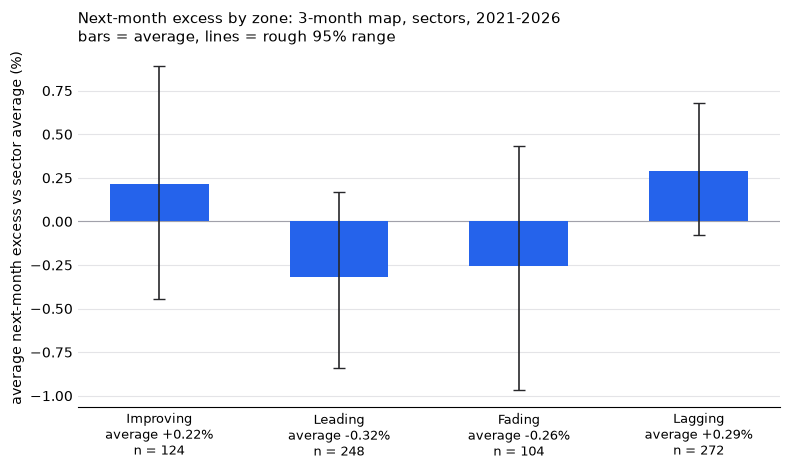

In [20]:
z = t1B[t1B.zone.isin(ZONES)].set_index("zone").reindex(ZONES)
fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(ZONES))
yerr = np.vstack([z.avg_excess_pct - z.range95_low_pct, z.range95_high_pct - z.avg_excess_pct])
ax.bar(x, z.avg_excess_pct, width=0.55, color="#2563eb", zorder=2)
ax.errorbar(x, z.avg_excess_pct, yerr=yerr, fmt="none", ecolor="#27272a", elinewidth=1.2, capsize=4, zorder=3)
ax.axhline(0, color="#a1a1aa", lw=0.8, zorder=1)
ax.set_xticks(x); ax.set_xticklabels([f"{zn}\naverage {a:+.2f}%\nn = {int(c):,}" for zn, a, c in zip(ZONES, z.avg_excess_pct, z["count"])], fontsize=9.5)
ax.set_ylabel("average next-month excess vs sector average (%)")
ax.grid(axis="y", color="#e4e4e7", lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.tick_params(length=0)
spanB = f"{mainT.date.min().year}-{dB.date.max().year}"
ax.set_title(f"Next-month excess by zone: 3-month map, sectors, {spanB}\nbars = average, lines = rough 95% range", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(R / "04b_avg_excess_by_zone.png", dpi=150); plt.show()

## B-10. Checks for the three Part B predictions

In [21]:
zB = t1B.set_index("zone").loc[ZONES]
inside = zB.avg_excess_pct.between(-0.5, 0.5)
print("Y1: average next-month excess by zone (need all four between -0.5% and +0.5%):")
print(zB[["count", "avg_excess_pct", "range95_low_pct", "range95_high_pct"]].round(3).to_string())
print(f"    -> {'CONFIRMED' if inside.all() else 'CONTRADICTED'} ({int(inside.sum())} of 4 zones inside the band)")
gap = realB["cw_share_of_one_step"] - nullB["cw_share_of_one_step"].mean()
print(f"Y2: real clockwise share {realB['cw_share_of_one_step']:.1f}% vs shuffled-days baseline {nullB['cw_share_of_one_step'].mean():.1f}% (2.5-97.5th pct {nullB['cw_share_of_one_step'].quantile(0.025):.1f} to {nullB['cw_share_of_one_step'].quantile(0.975):.1f}): difference {gap:+.2f} points (need within 3) -> {'CONFIRMED' if abs(gap) <= 3 else 'CONTRADICTED'}")
print(f"Y3: industries 3-month: Fading {fvoB['fading_avg_pct']:+.3f}% minus overall {fvoB['overall_avg_pct']:+.3f}% = {fvoB['fading_minus_overall_pct']:+.3f}% (need above 0); rough 95% range {fvoB['range95_low_pct']:+.3f}% to {fvoB['range95_high_pct']:+.3f}%; Fading n = {fvoB['n_fading']} of {fvoB['n_all']} -> {'CONFIRMED' if fvoB['fading_minus_overall_pct'] > 0 else 'CONTRADICTED'}")

Y1: average next-month excess by zone (need all four between -0.5% and +0.5%):
           count  avg_excess_pct  range95_low_pct  range95_high_pct
zone                                                               
Improving    124           0.216           -0.448             0.892
Leading      248          -0.319           -0.840             0.167
Fading       104          -0.258           -0.970             0.432
Lagging      272           0.290           -0.077             0.682
    -> CONFIRMED (4 of 4 zones inside the band)
Y2: real clockwise share 68.7% vs shuffled-days baseline 70.7% (2.5-97.5th pct 65.9 to 75.6): difference -2.00 points (need within 3) -> CONFIRMED
Y3: industries 3-month: Fading +0.214% minus overall +0.342% = -0.129% (need above 0); rough 95% range -1.635% to +1.483%; Fading n = 46 of 272 -> CONTRADICTED
